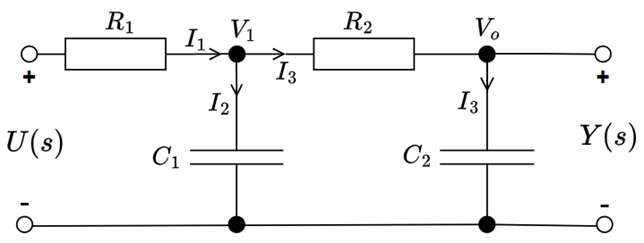

            พลานต์ (Plant) อันดับสองจากวงจร RC แบบสองขั้น

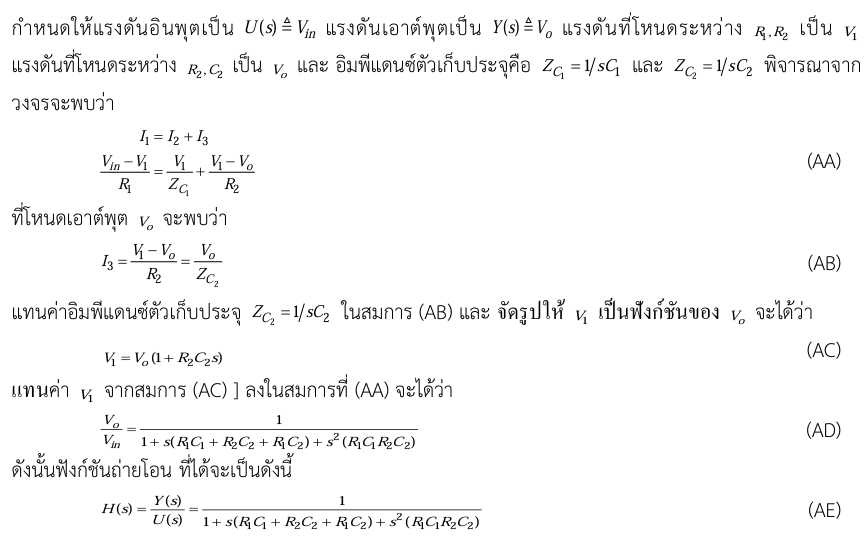

อนึ่ง สามารถใช้ google Colab เขียนโค๊ด python ในสไตน์  .ipynb เพื่อช่วยหาฟังก์ชันถ่ายโอน ได้ดังนี้

In [1]:
import sympy as sp

# ประกาศตัวแปรเชิงสัญลักษณ์
R1, R2, C1, C2, s, U, Y = sp.symbols('R1 R2 C1 C2 s U Y')

# นิยามแรงดันโหนดกลาง V1 จาก KCL ที่เอาต์พุต
V1 = Y * (1 + s*R2*C2)

# KCL ที่โหนด V1:
# (U - V1)/R1 = s*C1*V1 + (V1 - Y)/R2
expr = sp.Eq((U - V1)/R1, s*C1*V1 + (V1 - Y)/R2)

# แก้สมการหา Y ในรูปของ U
Ysol = sp.solve(expr, Y)[0]

# ฟังก์ชันถ่ายโอน H(s) = Y/U
Hs = sp.simplify(Ysol / U)

print("H(s) =", Hs)

# Extract the denominator of H(s)
denom_Hs = sp.denom(Hs)

# The standard form of a second-order transfer function is H(s) = K * ωn^2 / (s^2 + 2ζωn*s + ωn^2)
# First, normalize the denominator by dividing by the coefficient of s^2
# to match the standard form: s^2 + (2ζωn)*s + ωn^2

# Extract coefficients of s^2, s, and constant from the denominator
poly_denom = sp.Poly(denom_Hs, s)
coeffs = poly_denom.coeffs()

a = coeffs[0]  # Coefficient of s^2
b = coeffs[1]  # Coefficient of s
c = coeffs[2]  # Constant term

# Calculate natural frequency (ωn)
# ωn^2 = c/a => ωn = sqrt(c/a)
omega_n = sp.sqrt(c/a)
print("\nNatural Frequency (ωn) =", sp.simplify(omega_n))

# Calculate damping ratio (ζ)
# 2ζωn = b/a => ζ = (b/a) / (2ωn)
damping_ratio = (b/a) / (2 * omega_n)
print("Damping Ratio (ζ) =", sp.simplify(damping_ratio))

H(s) = 1/(C1*C2*R1*R2*s**2 + C1*R1*s + C2*R1*s + C2*R2*s + 1)

Natural Frequency (ωn) = sqrt(1/(C1*C2*R1*R2))
Damping Ratio (ζ) = sqrt(1/(C1*C2*R1*R2))*(C1*R1 + C2*R1 + C2*R2)/2
